1. Forward:  encoder → memory M → decoder → logits → loss
2. dlogits = (probs − onehot) / N
3. Backward through linear → decoder layers, top to bottom.
   In each decoder layer, in reverse order:
     Add&Norm → FFN → Add&Norm → cross-attention → Add&Norm → masked self-attn
   Each cross-attention gives a dM. Accumulate: dM_total += dM
4. Decoder embedding: np.add.at(dE_dec, ids, dx)
5. Use dM_total as the incoming gradient for the encoder's top layer
6. Backward through encoder layers, top to bottom
7. Encoder embedding: np.add.at(dE_enc, ids, dx)
8. Optimizer step on all weights

In [35]:
import numpy as np
from collections import Counter
import seaborn as sns
np.random.seed(40)

# model constants

In [36]:
d = 16
head = 4
h_d = d // head
units = 64

# Dummy train data

In [37]:
s1 = [("i","love","cats"),("j'","aime","les","chats")]
s2 = [("i","love","dogs"),("j'","aime","les","chiens")]
s3 = [("i","see","cats" ),("je","vois","les","chats")]
s4 = [("i","see","dogs" ),("je","vois","les","chiens")]
s5 = [("you","see","cats" ),("tu","vois","les","chats")]
s6 = [("you","see","dogs" ),("tu","vois","les","chiens")]

s7 = [("i","love","birds"),("j'","aime","les","oiseaux")]
s8 = [("i","love","fish"),("j'","aime","les","poissons")]
s9 = [("i","see","birds" ),("je","vois","les","oiseaux")]
s10 = [("i","see","fish" ),("je","vois","les","poissons")]
s11 = [("you","see","birds" ),("tu","vois","les","oiseaux")]
s12 = [("you","see","fish" ),("tu","vois","les","poissons")]

s13 = [("you","love","cats"),("tu","aimes","les","chats")] 

sentences = [s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13]

# Separating the English and French sentences

In [38]:
english = []
french = ["<bos>","<eos>"] #pre initialization with bos and eos
for i,j in sentences:
    english += [*i]
    french += [*j]

# Creating the vocab for the languages

In [39]:
def converter(word_list):
    word_count = Counter(word_list)
    word_idx = {word:idx for idx,word in enumerate(word_count.keys())}
    idx_word = {idx:word for idx,word in enumerate(word_count.keys())}
    return word_idx,idx_word

In [40]:
eng_word_idx,eng_idx_word = converter(english)
fre_word_idx,fre_idx_word = converter(french)

# Converting the raw tokens to numerical sequence

In [41]:
def sequence(sentences):
    pair = []
    for eng,fre in sentences:
        eng_seq = [eng_word_idx[key] for key in eng]
        fre_mod = ("<bos>",) + fre + ("<eos>",)
        fre_seq = [fre_word_idx[key] for key in fre_mod]

        pair.append([eng_seq,fre_seq[:-1],fre_seq[1:]])
    return pair

seq_pair = sequence(sentences)

# Max len( N ) and Vovab size( T )

In [42]:
eng_N = len(seq_pair[0][0])
eng_T = len(eng_word_idx)

fre_N = len(seq_pair[0][1])
fre_T = len(fre_word_idx)

# Creating the encoding table for both the languages

In [43]:
E_enc = np.random.randn(len(eng_word_idx), d)
F_enc = np.random.randn(len(fre_word_idx), d)

# creating positional embedding

In [44]:
def positional_emb(inp):
    pos_em = np.zeros_like(inp)
    shape = np.shape(inp)
    d = shape[1]
    for pos in range(shape[0]):
        for idx in range(d):
            if idx % 2 == 0:
                i = idx /2
                angle = pos / 10000 ** (2*i/d)
                val = np.sin(angle)
                pos_em[pos][idx] = val
            else:
                i = (idx - 1) / 2
                angle = pos / 10000 ** (2*i/d)
                val = np.cos(angle)
                pos_em[pos][idx] = val
    return pos_em

# Embedding + Positional Embedding

In [45]:
def embed(ids, table):
    x = table[ids]
    return x + positional_emb(x)

# Softmax

In [46]:
def softmax(matrix):
    ez = np.exp(matrix - np.max(matrix,axis=-1,keepdims=True))
    proba = ez/np.sum(ez,axis=-1,keepdims=True)
    return proba

    

# Multihead Class for both Self and Cross Attention

In [47]:
class MultiHead:

    def __init__(self,d:int,heads:int):
        #configue dimensions
        self.d = d
        self.heads = heads
        self.h_d = d // heads

        #saving the initial weights
        self.weight_bias = {}
        self.weight_bias['W_Q'] = np.random.randn(d,d)*0.1
        self.weight_bias['W_K'] = np.random.randn(d,d)*0.1
        self.weight_bias['W_V'] = np.random.randn(d,d)*0.1
        self.weight_bias['W_O'] = np.random.randn(d,d)*0.1
    
    def forward_propagation(self,q_in,k_in,v_in,mask=None):
        # Calculating Q, K and V
        # q_in/k_in/v_in : shape(3,4)
        # W_Q,W_K,W_V,W_O : shape(4,4)

        Q = q_in @ self.weight_bias['W_Q']
        K = k_in @ self.weight_bias['W_K']
        V = v_in @ self.weight_bias['W_V']

        heads_out,W_as = [],[]
        for i in range(0,self.d,self.h_d):
            s = slice(i,i+self.h_d)
            h_Q,h_K,h_V = Q[:,s],K[:,s],V[:,s]

            score =  (h_Q @ h_K.T) / np.sqrt(self.h_d) # (3,2) . (2,3) = (3,3)
            #masking for decoder self attention
            if mask is not None:
                score = score + mask
            W_a = softmax(score) #attention weights : shape(3,3) -- > attention given by each token to every other token
            W_as.append(W_a)
            head = W_a @ h_V
            heads_out.append(head)
        
        #concatenating the heads
        # head1/head2 : shape(3,2)
        concat = np.concatenate(heads_out,axis=1)
        #head : shape(3,4)

        #mixing the weights
        W_b = concat @ self.weight_bias['W_O'] # block weight 

        self.cache = {'Q':Q,'K':K,'V':V,'q_in':q_in,'k_in':k_in,'v_in':v_in,'concat':concat,
                        'otput_weight':W_b,'W_as':W_as}

        return W_b

    def backward_propagation(self,dout):
        #dummy gradient
        dWb = dout #dWb gradient =  dL/dWb comes from layer norm

        #step - 1
        dWo = self.cache['concat'].T @ dWb           
        dconcat = dWb @ self.weight_bias['W_O'].T

        #step - 2
        concat = self.cache['concat']

        concat_dQ,concat_dK,concat_dV = [],[],[]
    
        for i,j in enumerate(range(0,self.d,self.h_d)):
            s = slice(j,j+self.h_d)

            #step 3
            # dconcat = [ dhead1 | dhead2 | ... ]
            dhead = dconcat[:, s]
            h_v = self.cache['V'][:,s]
            dWa = dhead @ h_v.T
            dhV = self.cache['W_as'][i].T @ dhead

            #step 4 
            #W_a = ex/summation(ej)
            W_a = self.cache['W_as'][i]
            dscore = W_a * (dWa - (dWa * W_a).sum(axis=-1, keepdims=True))

            #step 5
            h_K = self.cache['K'][:,s]
            h_Q = self.cache['Q'][:,s]
            dhQ = dscore @ h_K / np.sqrt(self.h_d) 
            dhK = dscore.T @ h_Q / np.sqrt(self.h_d) 

            #step 6
            concat_dQ.append(dhQ)
            concat_dK.append(dhK)
            concat_dV.append(dhV)

        dQ = np.concat(concat_dQ,axis=1)
        dK = np.concat(concat_dK,axis=1)
        dV = np.concat(concat_dV,axis=1)

        #step 7
        dq_in = dQ @ self.weight_bias['W_Q'].T
        dk_in = dK @ self.weight_bias['W_K'].T
        dv_in = dV @ self.weight_bias['W_V'].T

        self.grads = {'W_Q': self.cache['q_in'].T @ dQ,
                'W_K': self.cache['k_in'].T @ dK,
                'W_V': self.cache['v_in'].T @ dV,
                'W_O': dWo}

        return dq_in, dk_in, dv_in




# Add + Normalization class

In [48]:
class AddNorm:
    def __init__(self,d):
        self.d = d
        self.gamma = np.ones(self.d)
        self.beta = np.zeros(self.d)
        self.esp = 1e-5

    def forward(self,X,sublayer):
        #residual layer
        r = X + sublayer

        #normalized layer
        m = np.mean(r,axis=-1,keepdims=True)
        v  = np.var(r,axis=-1,keepdims=True)
        std_inv = 1 / np.sqrt(v + self.esp)
        X_cap = (r - m) * (std_inv) 

        N = X_cap * self.gamma + self.beta
        self.cache = {'X_cap':X_cap,'residual':r,'output':N,'std_inv':std_inv}
        return N
    
    def backward(self,dnormalized):
        dN = dnormalized #shape(T,d)
        X_cap = self.cache['X_cap']
        
        # step 1
        dgamma = (dN * X_cap).sum(axis=0)
        dbeta = dN.sum(axis=0)
        dX_cap = dN  * self.gamma

        #step 2
        dr = self.cache['std_inv']*(dX_cap - dX_cap.mean(axis=-1, keepdims=True) 
                                    - X_cap*(dX_cap * X_cap).mean(axis=-1, keepdims=True))


        #step 3
        dX,dsublayer = dr,dr

        self.grads = {'gamma': dgamma, 'beta': dbeta}

        return dX,dsublayer


# ReLu function

In [49]:
def relu(Z):
    return np.maximum(0, Z)


# Dense class or Feed Forward Layer class

In [50]:
class Dense:
    def __init__(self,d,units):
        self.d = d
        self.units = units
        self.weight_bias = {'W1':np.random.randn(self.d,self.units),'Wb1':np.random.randn(self.units),
                            'W2':np.random.randn(self.units,self.d),'Wb2':np.random.randn(self.d)}
        
    def forward(self,output):
        #dense layer 1 - for exapanding
        Z1 = output @ self.weight_bias['W1'] + self.weight_bias['Wb1']
        d_out1 = relu(Z1)

        #dense layer 2 - for shrinking to oringinal dimension
        Z2 = d_out1 @ self.weight_bias['W2'] + self.weight_bias['Wb2']

        self.cache = {'Z1':Z1,'d_out1':d_out1,'Z2':Z2,'output':output}
        return Z2
    
    def backward(self,dZ2):
        #step 1
        ddout1 = dZ2 @ self.weight_bias['W2'].T
        dW2 = self.cache['d_out1'].T @ dZ2
        dWb2 = dZ2.sum(axis=0)

        #step 2
        #dl/dz1 = (dl/ddout1) * (ddout1/dz1) : for ddout1/dz1 -> 0 if Z <= 0 and 1 if Z > 0
        dZ1 = ddout1 * (self.cache['Z1'] > 0).astype(int)

        #step 3
        doutput = dZ1 @ self.weight_bias['W1'].T
        dW1 = self.cache['output'].T @ dZ1
        dWb1 = dZ1.sum(axis=0)

        self.grads = {'W2':dW2,'Wb2':dWb2,'W1':dW1,'Wb1':dWb1}

        return doutput
        
        


# Linear Class

In [51]:
class Linear():
    def __init__(self,d,vocab):
        self.vocab = vocab
        self.d = d
        self.W = np.random.randn(self.d,self.vocab) * 0.1
        self.b = np.random.randn(self.vocab) * 0.1

    def forward(self,X):
        # here each token : Based on everything I've seen so far, what information do I have at position 1?"
        # Z : what score should i give to each token for the vocab(max is chosen then)
        self.X = X
        Z = self.X @ self.W + self.b
        return Z

    def backward(self,dZ):
        dX = dZ @ self.W.T
        dW = self.X.T @ dZ
        db = np.sum(dZ,axis=0)

        self.grads = {'W':dW,'b':db}
        return dX
    


# Softmax + Cross Entropy

In [52]:
class SoftmaxCrossEntropy:
    def forward(self, Z, label=None):
        ez = np.exp(Z - Z.max(axis=-1, keepdims=True))
        self.prob = ez / ez.sum(axis=-1, keepdims=True)
        self.label = label
        return self.prob

    def loss(self):
        N = len(self.label)
        return -np.log(self.prob[np.arange(N), self.label] + 1e-12).mean()

    def backward(self):                              # fused gradient
        N = len(self.label)
        dZ = self.prob.copy()
        dZ[np.arange(N), self.label] -= 1
        return dZ / N

    def get_dprob(self):
        N = len(self.label)
        dprob = np.zeros_like(self.prob)
        dprob[np.arange(N), self.label] = -1 / (N * prob[np.arange(N), self.label])
        return dprob

    def backward_from_dprob(self, dprob):            # general softmax-only backward, kept for testing
        return self.prob * (dprob - (dprob * self.prob).sum(axis=-1, keepdims=True))




# Optimizer Adam class

In [53]:
class Adam:
    def __init__(self, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m, self.v, self.t = {}, {}, 0
    def step(self, params):                    # same order every call
        self.t += 1
        for i, (W, g) in enumerate(params):
            m = self.b1*self.m.get(i, 0) + (1-self.b1)*g
            v = self.b2*self.v.get(i, 0) + (1-self.b2)*g*g
            self.m[i], self.v[i] = m, v
            mh, vh = m/(1-self.b1**self.t), v/(1-self.b2**self.t)
            W -= self.lr * mh / (np.sqrt(vh) + self.eps)

# Loss function

In [54]:
def loss(prob,N,label):
    log_esp = 1e-12
    error = ((-np.log(prob[np.arange(N),label] + log_esp))).mean()
    return error


# standalone Forward Mechanism : returns probability (prob)

In [55]:
#encoder
en_attn,en_norm1,en_dense,en_norm2, = MultiHead(d,head),AddNorm(d),Dense(d,units),AddNorm(d) #encoder object
dec_attn,dec_norm1,dec_cattn,dec_norm2,dec_dense,dec_norm3 = MultiHead(d,head),AddNorm(d),MultiHead(d,head),AddNorm(d),Dense(d,units),AddNorm(d)
dec_linear = Linear(d,fre_T)
dec_softmax = SoftmaxCrossEntropy()

def forward(X,Y_in,Y_out):
    #encoder layers
    en_Wb = en_attn.forward_propagation(X,X,X)
    Enormalized = en_norm1.forward(X,en_Wb)
    Eout = en_dense.forward(Enormalized)
    memory = en_norm2.forward(Enormalized,Eout)


    #decoder layers
    N = Y_in.shape[0]
    mask = np.triu(np.full((N,N),fill_value=-1e9), k=1)

    dec_Wb1 = dec_attn.forward_propagation(Y_in,Y_in,Y_in,mask)
    Dnormalized1 = dec_norm1.forward(Y_in,dec_Wb1)
    dec_Wb2 = dec_cattn.forward_propagation(Dnormalized1,memory,memory)
    Dnormalized2 = dec_norm2.forward(Dnormalized1,dec_Wb2)
    Dout = dec_dense.forward(Dnormalized2)
    Dnormalized3 = dec_norm3.forward(Dnormalized2,Dout)
    
    Z = dec_linear.forward(Dnormalized3)
    prob = dec_softmax.forward(Z,Y_out)

    return prob


# standalone Backward Mechanism : returns Embedding gradients (dE,dF)

In [56]:
def backward(src_id,tin_id):

    dZ = dec_softmax.backward() # uses prob/label internally to calc dZ using the shortcut method
    dDnormalized3 = dec_linear.backward(dZ)
    dDnormalized2_1,dDout = dec_norm3.backward(dDnormalized3)
    dDnormalized2_2= dec_dense.backward(dDout)

    dDnormalized2 = dDnormalized2_1 + dDnormalized2_2

    dDnormalized1_1,ddec_Wb2 = dec_norm2.backward(dDnormalized2)
    dDnormalized1_2,dmemory1,dmemory2 = dec_cattn.backward_propagation(ddec_Wb2)

    dDnormalized1 = dDnormalized1_1 + dDnormalized1_2

    dY_in1,ddec_Wb1 = dec_norm1.backward(dDnormalized1)
    dY_in2,dY_in3,dY_in4 = dec_attn.backward_propagation(ddec_Wb1)

    dY_in =dY_in1 + dY_in2 + dY_in3 + dY_in4
    dmemory = dmemory1 + dmemory2

    dEnormalized_1,dEout = en_norm2.backward(dmemory)
    dEnormalized_2 =  en_dense.backward(dEout)

    dEnormalized = dEnormalized_1 + dEnormalized_2

    dX1,den_Wb = en_norm1.backward(dEnormalized)
    dX2,dX3,dX4 = en_attn.backward_propagation(den_Wb)

    dX = dX1 + dX2 + dX3 + dX4

    dE = np.zeros_like(E_enc); np.add.at(dE, src_id, dX)
    dF = np.zeros_like(F_enc); np.add.at(dF, tin_id, dY_in)

    return dE, dF


# Gradient testing 

The difference between manual gradient and Model gradient should be around 1e-11 to 1e-6

In [57]:
src, tin, tout = seq_pair[2]
def loss1():
    p = forward(embed(src, E_enc), embed(tin, F_enc), tout)
    return dec_softmax.loss()

loss1()

def check(arr, analytic, name, eps=1e-5):
    num = np.zeros_like(arr)
    for idx in np.ndindex(arr.shape):
        old = arr[idx]
        arr[idx] = old + eps; lp = loss1()
        arr[idx] = old - eps; lm = loss1()
        arr[idx] = old                      # exact restore
        num[idx] = (lp - lm) / (2 * eps)
    print(f'{name}: max abs diff = {np.abs(num - analytic).max():.2e}')

dE, dF = backward(src, tin)     # analytic, before any perturbing
check(E_enc, dE, 'enc embedding')                # point check's inner loss() call at loss1
check(en_attn.weight_bias['W_Q'], en_attn.grads['W_Q'], 'enc W_Q')
check(F_enc, dF, 'dec embedding')

enc embedding: max abs diff = 6.14e-11
enc W_Q: max abs diff = 4.68e-11
dec embedding: max abs diff = 4.62e-11


In [58]:
print(np.abs(dE).max(), np.abs(dF).max())     # encoder vs decoder embedding gradient

0.0020087250561803367 0.04544684643973937


# list of tuples of parameters and their gradients

In [59]:
def get_params(dE,dF):
    P = [] 

    for layer in (en_attn,en_dense,dec_attn,dec_cattn,dec_dense):
        for k,w in layer.weight_bias.items():
            P.append((w,layer.grads[k]))

    for layer in (en_norm1,en_norm2,dec_norm1,dec_norm2,dec_norm3):
        P += [(layer.gamma,layer.grads['gamma']),(layer.beta,layer.grads['beta'])]

    P += [(dec_linear.W,dec_linear.grads['W']),(dec_linear.b,dec_linear.grads['b'])]

    P += [(E_enc,dE),(F_enc,dF)]

    return P



# Training the model with Adam optimizer 

Both forward and backward steps are called. 

P.S. SGD optimizer was used but was insufficient

In [60]:
error = []

#TRAINING WITH ADAM
adam = Adam()
for epoch in range(1000):
    np.random.shuffle(seq_pair)
    total = 0
    for src_ids, tgt_in, tgt_out in seq_pair:
        src_em = embed(src_ids,E_enc)
        tin_em = embed(tgt_in,F_enc)
        prob = forward(src_em, tin_em,tgt_out)
        total += dec_softmax.loss()
        # total += loss(prob,len(tgt_out),tgt_out)
        dE, dF = backward(src_ids,tgt_in)
        adam.step(get_params(dE, dF))
        # for W, g in get_params(dE, dF):
        #     W -= lr * g
    error.append(total / len(seq_pair))
    

# Initial and Final error values and their difference

In [61]:
print(f'Initial Loss : {error[0]}')
print(f'Final Loss : {error[-1]}')
print(f'Difference  : {error[-1] - error[0]}')

Initial Loss : 2.303421935594497
Final Loss : 1.1850903024266805e-07
Difference  : -2.303421817085467


# Plotting Loss v/s Epoch graph

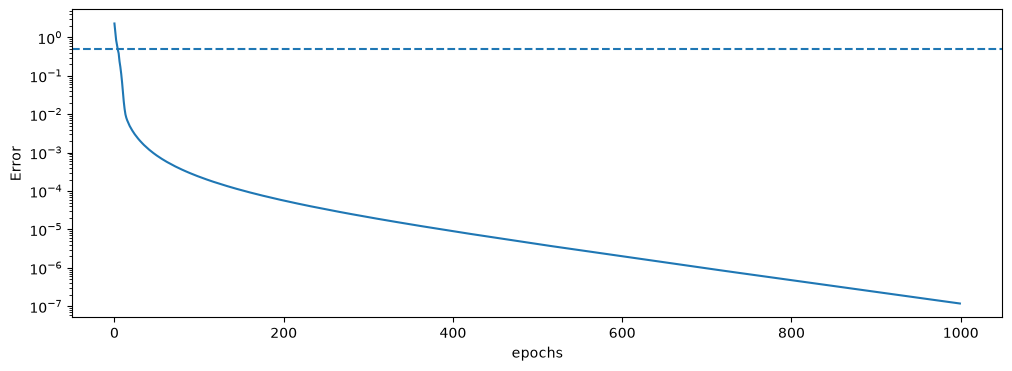

In [62]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(12,4))
plt.plot(error)
plt.yscale('log')
plt.axhline(0.51, ls='--') #horizontal line 
plt.xlabel('epochs')
plt.ylabel('Error')
plt.show()

# Encoder and Decoder for Inference and Testing

In [63]:
def encoder(X):
    en_Wb = en_attn.forward_propagation(X,X,X)
    Enormalized = en_norm1.forward(X,en_Wb)
    Eout = en_dense.forward(Enormalized)
    memory = en_norm2.forward(Enormalized,Eout)
    return memory

def decoder(Y_in,Y_out,memory):
    #decoder layers
    N = Y_in.shape[0]
    mask = np.triu(np.full((N,N),fill_value=-1e9), k=1)

    dec_Wb1 = dec_attn.forward_propagation(Y_in,Y_in,Y_in,mask)
    Dnormalized1 = dec_norm1.forward(Y_in,dec_Wb1)
    dec_Wb2 = dec_cattn.forward_propagation(Dnormalized1,memory,memory)
    Dnormalized2 = dec_norm2.forward(Dnormalized1,dec_Wb2)
    Dout = dec_dense.forward(Dnormalized2)
    Dnormalized3 = dec_norm3.forward(Dnormalized2,Dout)
    
    Z = dec_linear.forward(Dnormalized3)
    prob = dec_softmax.forward(Z,Y_out)
    return prob

    

# Function for Translating

In [64]:
def translate(src_ids,tout,bos=fre_word_idx['<bos>'], eos= fre_word_idx['<eos>'], max_len=10):
    memory = encoder(embed(src_ids, E_enc))
    out = [bos]
    for i in range(max_len):
        prob = decoder(embed(out, F_enc),tout, memory)
        nxt = int(prob[-1].argmax()) # last row = next-token distribution
        if nxt == eos:
            break
        out.append(nxt)
    return out[1:] # first element : <bos> removed



# Evaluating the model on whole Training data to measurre the accuracy

In [65]:
def evaluate(pairs):
    hits = 0
    seq = []
    for src,tin, tout in pairs:
        pred = translate(src,tout[:-1],max_len=len(tout) + 2)
        hits += (pred == list(tout[:-1]))          # exact match, <eos> included
        seq.append([tout[:-1],pred])
    return hits / len(pairs),seq

hits,seq  = evaluate(seq_pair)
print('Over all Accuracy : ',hits)

for s in seq:
    actual = [fre_idx_word[i] for i in s[0]]
    pred = [fre_idx_word[i] for i in s[1]]

    print(f'Individual/Positional Accuracy : {sum([a == p for a,p in zip(actual,pred)])/len(actual)}')
    print('Actual   : ',actual)
    print('Pred     : ',pred)
    print()

Over all Accuracy :  1.0
Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'vois', 'les', 'oiseaux']
Pred     :  ['tu', 'vois', 'les', 'oiseaux']

Individual/Positional Accuracy : 1.0
Actual   :  ["j'", 'aime', 'les', 'chats']
Pred     :  ["j'", 'aime', 'les', 'chats']

Individual/Positional Accuracy : 1.0
Actual   :  ['je', 'vois', 'les', 'oiseaux']
Pred     :  ['je', 'vois', 'les', 'oiseaux']

Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'vois', 'les', 'chats']
Pred     :  ['tu', 'vois', 'les', 'chats']

Individual/Positional Accuracy : 1.0
Actual   :  ['je', 'vois', 'les', 'chats']
Pred     :  ['je', 'vois', 'les', 'chats']

Individual/Positional Accuracy : 1.0
Actual   :  ["j'", 'aime', 'les', 'poissons']
Pred     :  ["j'", 'aime', 'les', 'poissons']

Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'vois', 'les', 'poissons']
Pred     :  ['tu', 'vois', 'les', 'poissons']

Individual/Positional Accuracy : 1.0
Actual   :  ["j'", 'aime', 'les', 'oiseaux']
Pred 

# Testing  the model on Never Seen Data and meaasure the accuracy

In [66]:
s14 = [("you","love","dogs"),("tu","aimes","les","chiens")]
s15 = [("you","love","birds"),("tu","aimes","les","oiseaux")]
s16= [("you","love","fish"),("tu","aimes","les","poissons")]

test_sen = [s14,s15,s16]
test_pair = [ ([eng_word_idx[i] for i in eng],[fre_word_idx[i] for i in fre]) for eng,fre in test_sen]

def evaluate_test(pairs):
    hits = 0
    seq = []
    for src, tout in pairs:
        pred = translate(src,tout,max_len=len(tout) + 2)
        hits += (pred == list(tout))          # exact match, <eos> included
        seq.append([tout,pred])
    return hits / len(pairs),seq

hits,seq  = evaluate_test(test_pair)
print('Over all Accuracy : ',hits)

for s in seq:
    actual = [fre_idx_word[i] for i in s[0]]
    pred = [fre_idx_word[i] for i in s[1]]

    print(f'Individual/Positional Accuracy : {sum([a == p for a,p in zip(actual,pred)])/len(actual)}') #checking the positional acc of each word
    print('Actual   : ',actual)
    print('Pred     : ',pred)
    print()

Over all Accuracy :  1.0
Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'aimes', 'les', 'chiens']
Pred     :  ['tu', 'aimes', 'les', 'chiens']

Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'aimes', 'les', 'oiseaux']
Pred     :  ['tu', 'aimes', 'les', 'oiseaux']

Individual/Positional Accuracy : 1.0
Actual   :  ['tu', 'aimes', 'les', 'poissons']
Pred     :  ['tu', 'aimes', 'les', 'poissons']



# Plotting HeatMap  for Cross Attention

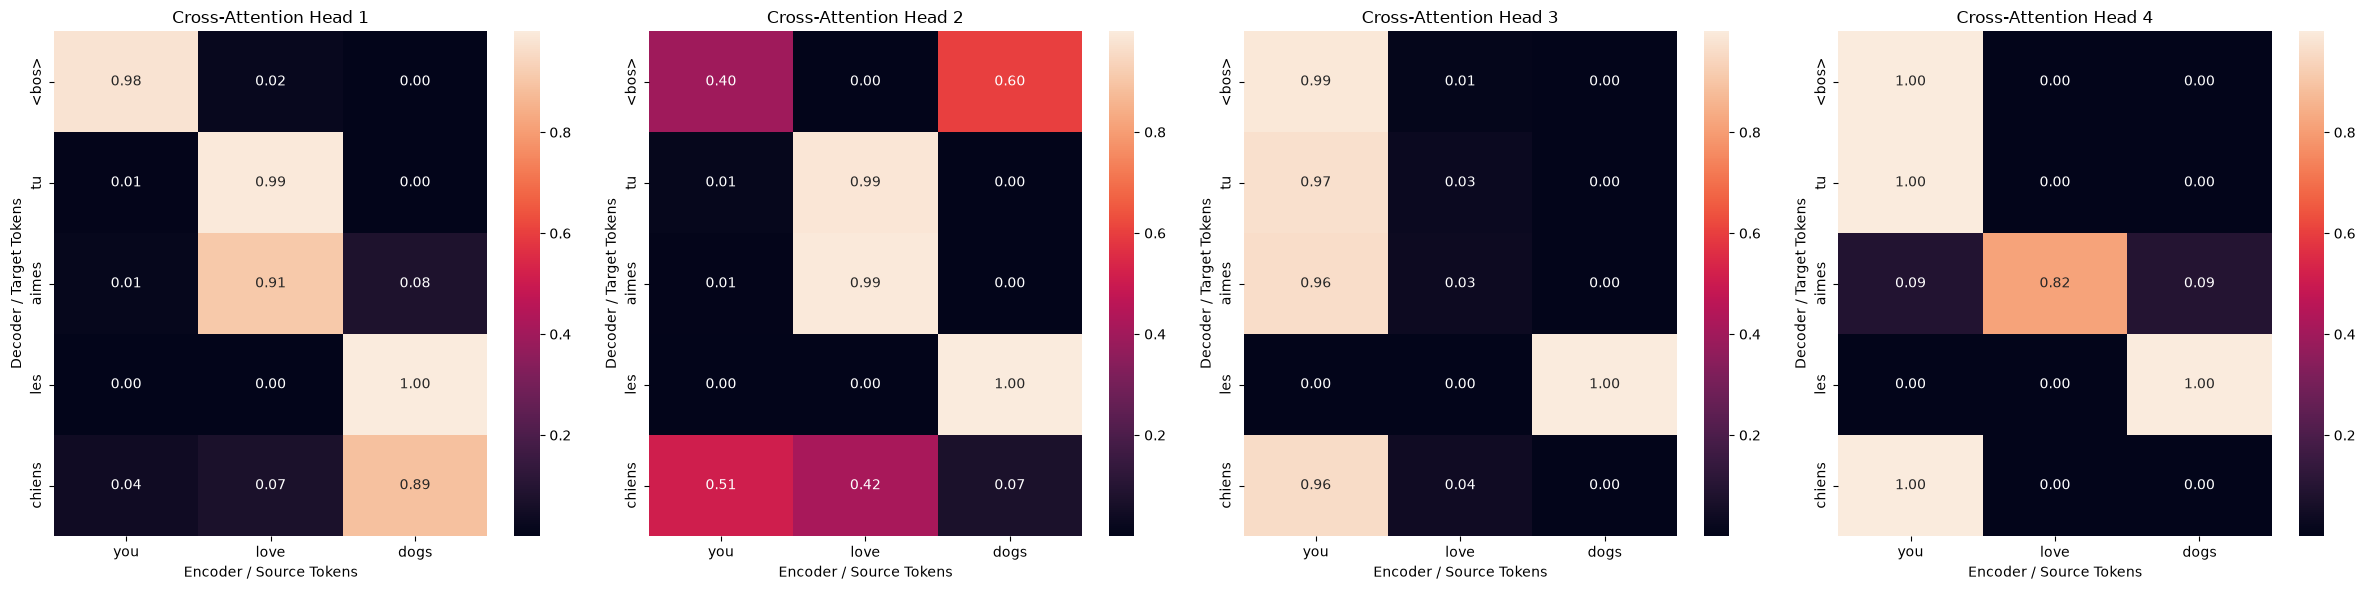

In [67]:
src_w, tin, tout = ['you','love','dogs'], ['<bos>','tu','aimes','les','chiens'], ['tu','aimes','les','chiens','<eos>']
forward(embed([eng_word_idx[w] for w in src_w], E_enc), embed([fre_word_idx[w] for w in tin], F_enc),embed([fre_word_idx[w] for w in tout], F_enc))

W_as = dec_cattn.cache['W_as']

fig, axes = plt.subplots(
    1, len(W_as),
    figsize=(6 * len(W_as), 6)
)

for h, ax in enumerate(axes):
    sns.heatmap(W_as[h], annot=True, fmt=".2f", ax=ax, xticklabels=src_w, yticklabels=tin,)
    ax.set_title(f"Cross-Attention Head {h + 1}")
    ax.set_xlabel("Encoder / Source Tokens")
    ax.set_ylabel("Decoder / Target Tokens")

plt.tight_layout()
plt.show()